# Divorce Analysis — Classification with logistic regression (4.3, 4.4, 4.5)

Predicts `DIVINYR` (divorced in the past year) from the cleaned, non-leaky features, step by step:

1. Load the cleaned CSV (same file as the clustering notebook)
2. Build the feature matrix (z-scores per year, one-hot with a reference level, missing flags)
3. Baseline: a model that always predicts "not divorced"
4. Logistic regression with default settings, 5-fold cross-validation
5. Hyperparameter tuning (grid search), then the same cross-validation again
6. Final model on all training rows, evaluated once on the test rows
7. Interpretation: odds ratios, and the age profile
8. One model per year: how the odds ratios changed between 2008, 2016 and 2024
9. Feature selection: full vs reduced (mutual information) set
10. Save results

**Metrics.** Only about 1% of people divorced in the past year, so accuracy is misleading: predicting "no" for
everyone is 99% accurate. The main metrics are **PR-AUC** (average precision; a random model scores the divorce
rate, about 0.01), **recall**, **precision** and **F1** for the divorced class, plus **ROC-AUC**.

**Test rows** (`SPLIT = test`) are used only in step 6 and later. Every choice (hyperparameters, the decision
threshold) is made on training rows.

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

DATA_PATH = Path("divorce_cleaned.csv")
REDUCED_SET_CSV = Path("report_outputs/final_reports_no_leakage/final_feature_sets.csv")  # from the MI step
OUT_DIR = Path("report_outputs/classification")

SEED = 0
CV_FOLDS = 5
CV_ROWS = 1_000_000          # training rows used for cross-validation (None = all; slower)
TUNE_ROWS = 500_000          # training rows used for the grid search
PARAM_GRID = {"C": [0.001, 0.01, 0.1, 1, 10],          # inverse regularisation strength
              "class_weight": ["balanced", None]}      # balanced = up-weight the rare divorced class
USE_PERWT = False            # True: fit with the ACS person weights (odds ratios describe the US population)
ADD_AGE_SQUARED = True       # divorce rises and falls with age: a squared term lets the model bend
N_JOBS = -1                  # parallel jobs for the grid search (-1 = all cores)
CHUNK = 500_000

CAT_VARS = ["HHTYPE", "REGION", "STATEFIP", "METRO", "OWNERSHP", "COUPLETYPE", "SEX", "MARST",
            "MARRNO", "RACE", "EDUC", "EMPSTAT", "LABFORCE", "CLASSWKR", "WKSWORK2", "MIGRATE1"]

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a9a"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Load the cleaned data

In [3]:
header = pd.read_csv(DATA_PATH, nrows=0).columns
df = pd.read_csv(DATA_PATH, keep_default_na=False,          # keep "N/A" as a real level, not a blank
                 dtype={c: "category" for c in CAT_VARS if c in header})
# df = df.rename(columns={"SPLIT": "SPLIT"})
# df["SPLIT"] = df["SPLIT"].astype(str).str.lower()

META = ["YEAR", "PERWT", "DIVINYR", "SPLIT"]
FLAG_COLS = [c for c in df.columns if c.endswith("_MISSING")]
CAT_COLS = [c for c in df.columns if isinstance(df[c].dtype, pd.CategoricalDtype)]
NUM_COLS = [c for c in df.columns if c not in META + FLAG_COLS + CAT_COLS]

leaky = [c for c in ["MARST", "HHTYPE", "MIGRATE1"] if c in df.columns]
if leaky:
    print(f"WARNING: {leaky} record the divorce itself (target leakage). Re-run preprocessing with "
          "exclude_situational=True before modelling.")

train = df["SPLIT"].eq("train").to_numpy()
tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(~train)
y_all, year_all, w_all = df["DIVINYR"].to_numpy().astype(int), df["YEAR"].to_numpy(), df["PERWT"].to_numpy()
y_tr, y_te = y_all[tr_idx], y_all[te_idx]
print(f"{len(df):,} rows: {len(tr_idx):,} training, {len(te_idx):,} test")
print(f"Divorced: {y_tr.mean():.3%} of training rows, {y_te.mean():.3%} of test rows")
print(f"Numeric ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Missing indicators: {FLAG_COLS}")

5,641,835 rows: 4,513,467 training, 1,128,368 test
Divorced: 1.059% of training rows, 1.059% of test rows
Numeric (11): ['AGE', 'FAMSIZE', 'NCHILD', 'UHRSWORK', 'YRMARR', 'RENT', 'VALUEH', 'INCTOT', 'FTOTINC', 'INCEARN', 'POVERTY']
Categorical (10): ['REGION', 'METRO', 'OWNERSHP', 'SEX', 'MARRNO', 'RACE', 'EDUC', 'EMPSTAT', 'CLASSWKR', 'WKSWORK2']
Missing indicators: ['FTOTINC_POVERTY_MISSING']


## 2. Feature matrix

* **Numeric:** z-score within each year, using that year's training rows, so a coefficient means "per 1 SD above
  that year's average" and inflation between years drops out. Optionally `AGE^2` (squared age z-score).
* **Categorical:** one 0/1 column per level, **minus one reference level per variable** (the most common level in
  the training rows). Each odds ratio then reads "compared with the reference group". Keeping every level would
  make the columns of a variable sum to 1, the same as the intercept, so the coefficients would not be unique.
* **Missing indicators** stay 0/1.

In [4]:
MEAN = df.loc[train].groupby("YEAR")[NUM_COLS].mean()
SD = df.loc[train].groupby("YEAR")[NUM_COLS].std(ddof=0).replace(0, 1)
REF = {v: df.loc[train, v].value_counts().idxmax() for v in CAT_COLS}
REF_COLS = {f"{v}__{REF[v]}" for v in CAT_COLS}
print("Reference level per categorical variable (most common in the training rows):")
display(pd.Series(REF, name="reference level").to_frame())

def encode(frame):
    yrs = frame["YEAR"].to_numpy()
    z = (frame[NUM_COLS].to_numpy("float64") - MEAN.loc[yrs].to_numpy()) / SD.loc[yrs].to_numpy()
    parts, names = [z], list(NUM_COLS)
    if ADD_AGE_SQUARED and "AGE" in NUM_COLS:
        parts.append(z[:, [NUM_COLS.index("AGE")]] ** 2); names.append("AGE^2")
    parts.append(frame[FLAG_COLS].to_numpy("float64")); names += FLAG_COLS
    hot = pd.get_dummies(frame[CAT_COLS], prefix_sep="__", dtype="float32")   # category dtype: every level
    hot = hot[[c for c in hot.columns if c not in REF_COLS]]
    parts.append(hot.to_numpy()); names += list(hot.columns)
    return np.hstack(parts).astype("float32"), names

FEATURES = encode(df.iloc[:1])[1]

def variable_of(name):
    # which original variable a column belongs to (used for the reduced set and for grouping)
    if "__" in name:
        return name.split("__")[0]
    if name == "AGE^2":
        return "AGE"
    return name

FEATURE_VARS = [variable_of(f) for f in FEATURES]

def build_matrix(rows):
    X = np.empty((len(rows), len(FEATURES)), dtype="float32")
    for i in range(0, len(rows), CHUNK):
        X[i:i + CHUNK] = encode(df.iloc[rows[i:i + CHUNK]])[0]
    return X

t0 = time.time()
X_tr, X_te = build_matrix(tr_idx), build_matrix(te_idx)
print(f"{len(FEATURES)} columns | training {X_tr.shape}, test {X_te.shape} "
      f"({(X_tr.nbytes + X_te.nbytes) / 1e9:.2f} GB), built in {time.time() - t0:.0f}s")

if USE_PERWT:
    sw_tr = (w_all[tr_idx] / w_all[tr_idx].mean()).astype("float64")    # scaled to mean 1
else:
    sw_tr = None

rng = np.random.default_rng(SEED)
def sample(n):
    return np.sort(rng.choice(len(tr_idx), size=len(tr_idx) if n is None else min(n, len(tr_idx)), replace=False))

cv_pos, tune_pos = sample(CV_ROWS), sample(TUNE_ROWS)

Reference level per categorical variable (most common in the training rows):


,reference level
REGION,South Atlantic Division
METRO,In metropolitan area: Central/principal city s...
OWNERSHP,Owned or being bought (loan)
SEX,Female
MARRNO,Married once
RACE,White
EDUC,Grade 12
EMPSTAT,Employed
CLASSWKR,Works for wages
WKSWORK2,50-52 weeks


58 columns | training (4513467, 58), test (1128368, 58) (1.31 GB), built in 4s


## 3–4. Baseline and default logistic regression (5-fold cross-validation)

Cross-validation splits the training sample into 5 parts, trains on 4 and scores the 5th, five times. The spread
across folds shows how consistent the model is. Precision, recall and F1 use a 0.5 probability threshold here;
step 5 picks a better threshold.

In [5]:
def metrics(y_true, prob, thr=0.5):
    pred = prob >= thr
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob)}

def run_cv(make_model, X, y, sw=None):
    # stratified k-fold: returns per-fold metrics and the out-of-fold probabilities
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
    rows, oof = [], np.zeros(len(y))
    for fold, (a, b) in enumerate(skf.split(X, y), 1):
        t0 = time.time()
        model = make_model()
        model.fit(X[a], y[a], **({} if sw is None else {"sample_weight": sw[a]}))
        oof[b] = model.predict_proba(X[b])[:, 1]
        rows.append({"fold": fold, **metrics(y[b], oof[b]), "fit_seconds": time.time() - t0})
    return pd.DataFrame(rows).set_index("fold"), oof

def summary(folds):
    return folds.agg(["mean", "std"]).T.rename(columns={"mean": "mean", "std": "std across folds"})

X_cv, y_cv = X_tr[cv_pos], y_tr[cv_pos]
sw_cv = None if sw_tr is None else sw_tr[cv_pos]
print(f"Cross-validation on {len(cv_pos):,} training rows ({y_cv.mean():.3%} divorced)")

base_folds, _ = run_cv(lambda: DummyClassifier(strategy="prior"), X_cv, y_cv)
print("Baseline (always predicts the divorce rate, i.e. 'not divorced'):")
display(summary(base_folds).round(4))

default_params = {"C": 1.0, "class_weight": "balanced"}
lr_folds, _ = run_cv(lambda: LogisticRegression(max_iter=1000, **default_params), X_cv, y_cv, sw_cv)
print(f"Logistic regression, default settings {default_params}, per fold:")
display(lr_folds.round(4))
display(summary(lr_folds).round(4))

Cross-validation on 1,000,000 training rows (1.052% divorced)
Baseline (always predicts the divorce rate, i.e. 'not divorced'):


,mean,std across folds
accuracy,0.9895,0.0000
precision,0.0000,0.0000
recall,0.0000,0.0000
f1,0.0000,0.0000
roc_auc,0.5000,0.0000
pr_auc,0.0105,0.0000
fit_seconds,0.1513,0.0686


Logistic regression, default settings {'C': 1.0, 'class_weight': 'balanced'}, per fold:


,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
fold,,,,,,,
1,0.6928,0.0249,0.7385,0.0481,0.7847,0.0417,5.7492
2,0.6905,0.0252,0.7556,0.0488,0.7924,0.0400,7.7688
3,0.6916,0.0249,0.7432,0.0482,0.7822,0.0395,5.5883
4,0.6888,0.0247,0.7442,0.0479,0.7871,0.0450,7.9348
5,0.6908,0.0251,0.7499,0.0485,0.7900,0.0418,6.1538


,mean,std across folds
accuracy,0.6909,0.0015
precision,0.0250,0.0002
recall,0.7463,0.0066
f1,0.0483,0.0004
roc_auc,0.7873,0.0041
pr_auc,0.0416,0.0021
fit_seconds,6.6390,1.1277


## 5. Hyperparameter tuning (4.5)

Grid search over the regularisation strength `C` (smaller = simpler model, coefficients pulled towards 0) and
`class_weight` (`balanced` up-weights the rare class). Each combination is scored by 3-fold cross-validated
**PR-AUC** on a training sample. PR-AUC does not depend on a threshold, so the threshold is chosen afterwards: the
one that maximises F1 on the out-of-fold predictions of the tuned model (training rows only).

In [6]:
t0 = time.time()
search = GridSearchCV(LogisticRegression(max_iter=1000), PARAM_GRID, scoring="average_precision",
                      cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=N_JOBS)
search.fit(X_tr[tune_pos], y_tr[tune_pos], **({} if sw_tr is None else {"sample_weight": sw_tr[tune_pos]}))
print(f"Grid search: {len(search.cv_results_['params'])} combinations x 3 folds on {len(tune_pos):,} rows, "
      f"{(time.time() - t0) / 60:.1f} min")
grid = (pd.DataFrame(search.cv_results_)
          [["param_C", "param_class_weight", "mean_test_score", "std_test_score", "mean_fit_time"]]
          .rename(columns={"mean_test_score": "pr_auc_mean", "std_test_score": "pr_auc_std"})
          .sort_values("pr_auc_mean", ascending=False))
display(grid.round(4).reset_index(drop=True))
best_params = search.best_params_
print("Best:", best_params)

tuned_folds, oof = run_cv(lambda: LogisticRegression(max_iter=1000, **best_params), X_cv, y_cv, sw_cv)

prec, rec, thr = precision_recall_curve(y_cv, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
THRESHOLD = float(thr[np.argmax(f1s)])
tuned_at_thr = pd.DataFrame([metrics(y_cv[b], oof[b], THRESHOLD) for _, b in
                             StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(X_cv, y_cv)])
print(f"Decision threshold that maximises F1 on the out-of-fold predictions: {THRESHOLD:.3f}")

compare = pd.DataFrame({
    "baseline": base_folds.mean(),
    "default (threshold 0.5)": lr_folds.mean(),
    "tuned (threshold 0.5)": tuned_folds.mean(),
    f"tuned (threshold {THRESHOLD:.3f})": tuned_at_thr.mean()}).drop("fit_seconds", errors="ignore")
print("Before vs after tuning (mean over the 5 folds):")
display(compare.round(4))

Grid search: 10 combinations x 3 folds on 500,000 rows, 0.3 min


,param_C,param_class_weight,pr_auc_mean,pr_auc_std,mean_fit_time
0,1.000,None,0.0540,0.0030,1.8100
1,10.000,None,0.0539,0.0030,1.5555
2,0.100,None,0.0537,0.0031,1.8739
3,0.010,None,0.0514,0.0035,1.8587
4,0.001,None,0.0405,0.0025,2.7457
5,0.001,balanced,0.0400,0.0024,4.4719
6,0.010,balanced,0.0397,0.0024,5.6350
7,0.100,balanced,0.0395,0.0023,4.6994
8,1.000,balanced,0.0395,0.0023,4.4274
9,10.000,balanced,0.0395,0.0023,3.3999


Best: {'C': 1, 'class_weight': None}
Decision threshold that maximises F1 on the out-of-fold predictions: 0.050
Before vs after tuning (mean over the 5 folds):


,baseline,default (threshold 0.5),tuned (threshold 0.5),tuned (threshold 0.050)
accuracy,0.9895,0.6909,0.9895,0.9685
f1,0.0000,0.0483,0.0000,0.1289
pr_auc,0.0105,0.0416,0.0559,0.0559
precision,0.0000,0.0250,0.0000,0.0909
recall,0.0000,0.7463,0.0000,0.2215
roc_auc,0.5000,0.7873,0.7892,0.7892


## 6. Final model: all training rows, evaluated on the test rows

The tuned model is refitted on all training rows and scored **once** on the test rows, with the threshold chosen
in step 5.

Final fit on 4,513,467 rows: 23s, 23 iterations


,threshold 0.5,threshold 0.050 (from training),baseline
accuracy,0.9894,0.9686,0.9894
precision,0.0000,0.0939,0.0000
recall,0.0000,0.2269,0.0000
f1,0.0000,0.1328,0.0000
roc_auc,0.7923,0.7923,0.5000
pr_auc,0.0587,0.0587,0.0106


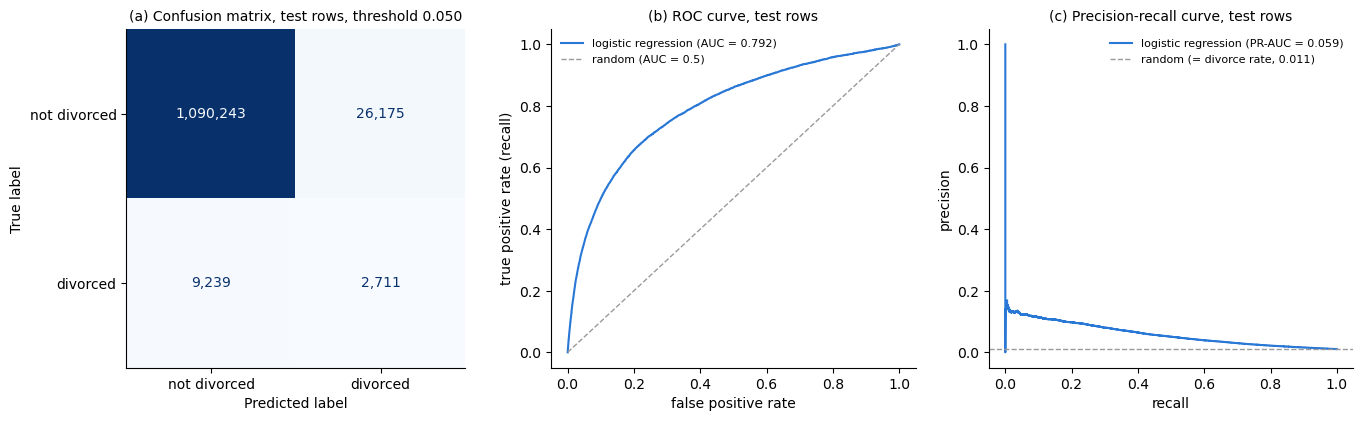

In [7]:
t0 = time.time()
final = LogisticRegression(max_iter=1000, **best_params)
final.fit(X_tr, y_tr, **({} if sw_tr is None else {"sample_weight": sw_tr}))
fit_full_seconds = time.time() - t0
p_te = final.predict_proba(X_te)[:, 1]
print(f"Final fit on {len(X_tr):,} rows: {fit_full_seconds:.0f}s, {final.n_iter_[0]} iterations")

test_scores = pd.DataFrame({"threshold 0.5": metrics(y_te, p_te, 0.5),
                            f"threshold {THRESHOLD:.3f} (from training)": metrics(y_te, p_te, THRESHOLD),
                            "baseline": metrics(y_te, np.full(len(y_te), y_tr.mean()))})
display(test_scores.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
cm = confusion_matrix(y_te, p_te >= THRESHOLD)
ConfusionMatrixDisplay(cm, display_labels=["not divorced", "divorced"]).plot(ax=axes[0], cmap="Blues",
                                                                              values_format=",", colorbar=False)
axes[0].set_title(f"(a) Confusion matrix, test rows, threshold {THRESHOLD:.3f}", fontsize=10)
fpr, tpr, _ = roc_curve(y_te, p_te)
axes[1].plot(fpr, tpr, color=BLUE, label=f"logistic regression (AUC = {roc_auc_score(y_te, p_te):.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="random (AUC = 0.5)")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("(b) ROC curve, test rows", fontsize=10); axes[1].legend(frameon=False, fontsize=8)
pp, rr, _ = precision_recall_curve(y_te, p_te)
axes[2].plot(rr, pp, color=BLUE, label=f"logistic regression (PR-AUC = {average_precision_score(y_te, p_te):.3f})")
axes[2].axhline(y_te.mean(), color=GREY, ls="--", lw=1, label=f"random (= divorce rate, {y_te.mean():.3f})")
axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision")
axes[2].set_title("(c) Precision-recall curve, test rows", fontsize=10); axes[2].legend(frameon=False, fontsize=8)
save_fig(fig, "logreg_test_evaluation")

,top_% by predicted risk,people,divorce_rate_% (= precision),times_average_rate (lift),% of all divorces captured (= recall),threshold
0,1.0,11284,11.264,10.636,10.636,0.070
1,5.0,56418,7.281,6.875,34.377,0.037
2,10.0,112837,5.180,4.891,48.912,0.026
3,20.0,225674,3.447,3.255,65.105,0.016
4,30.0,338510,2.611,2.465,73.958,0.011
5,50.0,564184,1.817,1.716,85.808,0.006


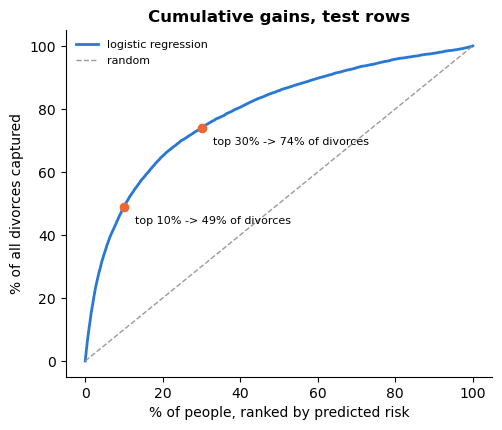

In [8]:
# How concentrated are divorces among the people the model ranks as most at risk? (test rows)
order = np.argsort(-p_te)
n, n_div = len(p_te), y_te.sum()
lift = []
for share in [0.01, 0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(round(share * n)); top = order[:k]
    lift.append({"top_% by predicted risk": 100 * share, "people": k,
                 "divorce_rate_% (= precision)": 100 * y_te[top].mean(),
                 "times_average_rate (lift)": y_te[top].mean() / y_te.mean(),
                 "% of all divorces captured (= recall)": 100 * y_te[top].sum() / n_div,
                 "threshold": p_te[order[k - 1]]})
lift = pd.DataFrame(lift)
display(lift.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
x = np.arange(1, n + 1) / n
ax.plot(100 * x, 100 * np.cumsum(y_te[order]) / n_div, color=BLUE, lw=2, label="logistic regression")
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="random")
for _, r in lift[lift["top_% by predicted risk"].isin([10, 30])].iterrows():
    ax.plot(r["top_% by predicted risk"], r["% of all divorces captured (= recall)"], "o", color=ORANGE)
    ax.annotate(f"top {r['top_% by predicted risk']:.0f}% -> {r['% of all divorces captured (= recall)']:.0f}% of divorces",
                (r["top_% by predicted risk"], r["% of all divorces captured (= recall)"]),
                textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.set_xlabel("% of people, ranked by predicted risk"); ax.set_ylabel("% of all divorces captured")
ax.set_title("Cumulative gains, test rows", fontweight="bold"); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "logreg_cumulative_gains")
lift.to_csv(OUT_DIR / "lift_table.csv", index=False)

## 7. Interpretation: odds ratios

`odds ratio = exp(coefficient)`. Above 1 = higher odds of a recent divorce, below 1 = lower, holding the other
variables constant. Numeric variables: per +1 SD above that year's average. Categorical levels: compared with the
reference level listed in step 2. With 4.5 million rows, almost every coefficient is statistically
significant, so the **size** of the odds ratio is what matters. AGE and AGE^2 only make sense together: see the
age profile below.

,feature,variable,coefficient,odds_ratio,compared_with
0,FAMSIZE,FAMSIZE,-1.100,0.333,per +1 SD
1,AGE,AGE,-0.641,0.527,per +1 SD
2,INCTOT,INCTOT,0.616,1.852,per +1 SD
3,MARRNO__Married thrice (or more),MARRNO,0.602,1.826,MARRNO = Married once
4,NCHILD,NCHILD,0.577,1.780,per +1 SD
5,FTOTINC,FTOTINC,-0.529,0.589,per +1 SD
6,YRMARR,YRMARR,0.518,1.679,per +1 SD
7,MARRNO__Married twice (or more),MARRNO,0.322,1.380,MARRNO = Married once
8,OWNERSHP__Rented,OWNERSHP,0.312,1.366,OWNERSHP = Owned or being bought (loan)
9,OWNERSHP__N/A,OWNERSHP,0.306,1.358,OWNERSHP = Owned or being bought (loan)


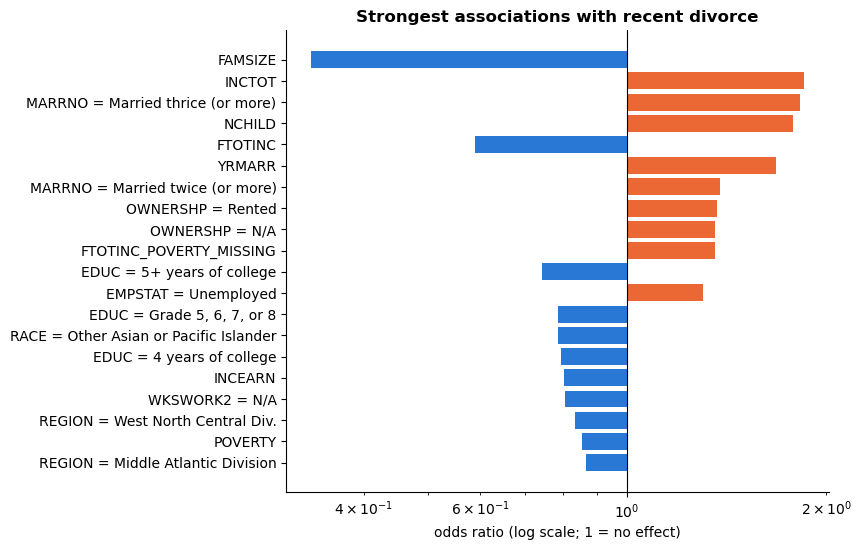

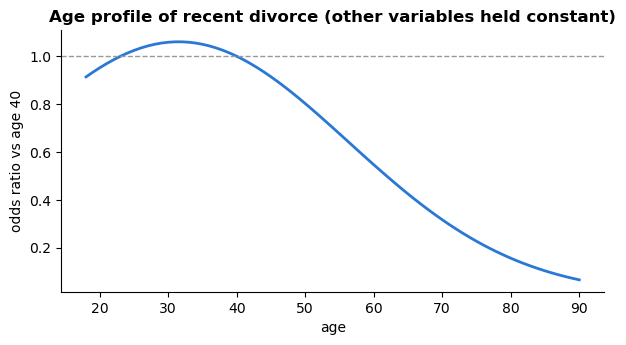

In [9]:
coef = pd.DataFrame({"feature": FEATURES, "variable": FEATURE_VARS, "coefficient": final.coef_[0]})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef["compared_with"] = [f"{v} = {REF[v]}" if "__" in f else ("per +1 SD" if f in NUM_COLS else "")
                         for f, v in zip(coef.feature, coef.variable)]
coef = coef.reindex(coef["coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
with pd.option_context("display.max_rows", 40, "display.max_colwidth", 60):
    display(coef.head(30).round(3))

top = coef[~coef.feature.isin(["AGE", "AGE^2"])].head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.feature.str.replace("__", " = "), top.odds_ratio - 1, left=1,
        color=[ORANGE if o > 1 else BLUE for o in top.odds_ratio])
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("odds ratio (log scale; 1 = no effect)")
ax.set_title("Strongest associations with recent divorce", fontweight="bold")
save_fig(fig, "logreg_odds_ratios")

if "AGE" in NUM_COLS:
    ages = np.arange(18, 91)
    mu, sd = MEAN["AGE"].mean(), SD["AGE"].mean()          # average over the years, for the x-axis in years
    z = (ages - mu) / sd
    b1 = coef.set_index("feature").loc["AGE", "coefficient"]
    b2 = coef.set_index("feature").coefficient.get("AGE^2", 0.0)
    logit = b1 * z + b2 * z ** 2
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(ages, np.exp(logit - logit[ages == 40][0]), color=BLUE, lw=2)
    ax.axhline(1, color=GREY, ls="--", lw=1)
    ax.set_xlabel("age"); ax.set_ylabel("odds ratio vs age 40")
    ax.set_title("Age profile of recent divorce (other variables held constant)", fontweight="bold")
    save_fig(fig, "logreg_age_profile")

## 8. One model per year: what changed between 2008, 2016 and 2024

The tuned model is refitted on each year's training rows. Because the numeric variables are z-scored within each
year, the odds ratios are comparable across years.

2008: 1,427,243 rows, 7s
2016: 1,475,710 rows, 6s
2024: 1,610,514 rows, 6s


,2008,2016,2024
FAMSIZE,0.29,0.36,0.36
INCTOT,1.92,1.76,1.74
MARRNO__Married thrice (or more),1.78,1.81,1.80
NCHILD,1.97,1.66,1.70
FTOTINC,0.56,0.62,0.59
YRMARR,1.86,1.63,1.56
MARRNO__Married twice (or more),1.42,1.39,1.33
OWNERSHP__Rented,1.29,1.31,1.45
OWNERSHP__N/A,1.30,1.28,1.47
FTOTINC_POVERTY_MISSING,1.30,1.28,1.47


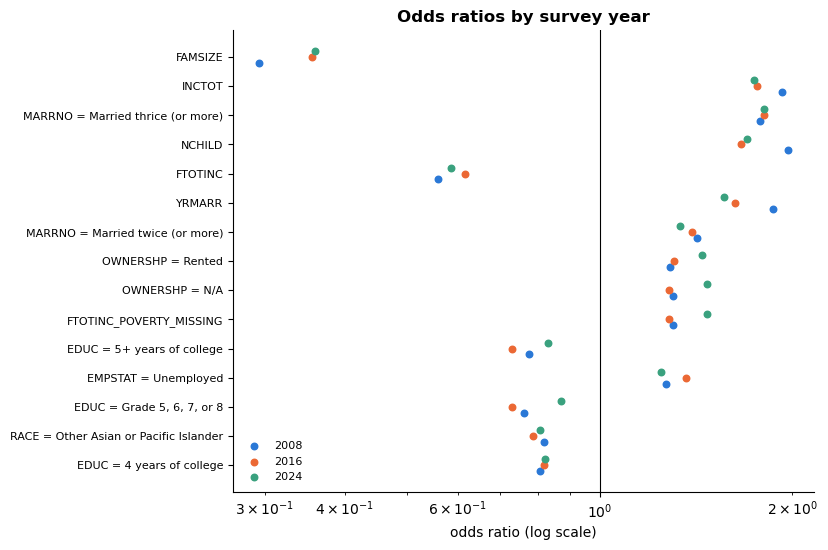

In [10]:
years = sorted(np.unique(year_all))
yr_tr = year_all[tr_idx]
or_by_year = {}
for yr in years:
    m = yr_tr == yr
    t0 = time.time()
    model = LogisticRegression(max_iter=1000, **best_params)
    model.fit(X_tr[m], y_tr[m], **({} if sw_tr is None else {"sample_weight": sw_tr[m]}))
    or_by_year[yr] = np.exp(model.coef_[0])
    print(f"{yr}: {int(m.sum()):,} rows, {time.time() - t0:.0f}s")
or_year = pd.DataFrame(or_by_year, index=FEATURES)

show = [f for f in coef.feature if f not in ("AGE", "AGE^2")][:15]
display(or_year.loc[show].round(2))

fig, ax = plt.subplots(figsize=(7.5, 6))
pos = np.arange(len(show))[::-1]
for i, yr in enumerate(years):
    ax.scatter(or_year.loc[show, yr], pos + (i - 1) * 0.2, s=22, label=str(yr),
               color=[BLUE, ORANGE, "#3aa17e", "#8e6bbf"][i % 4])
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_yticks(pos, [s.replace("__", " = ") for s in show], fontsize=8)
ax.set_xlabel("odds ratio (log scale)")
ax.set_title("Odds ratios by survey year", fontweight="bold")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "logreg_odds_ratios_by_year")

## 9. Feature selection: full vs reduced set (4.3)

The reduced set is the top variables by mutual information (preprocessing notebook). The same tuned model is
cross-validated and refitted on those columns only, and compared with the full set on performance and training
time.

In [12]:
if REDUCED_SET_CSV.exists():
    fs = pd.read_csv(REDUCED_SET_CSV)
    REDUCED_VARS = set(fs.loc[fs["in_reduced_set"].astype(str).str.lower() == "true", "variable"])
else:
    REDUCED_VARS = REDUCED_VARS = {"YRMARR", "AGE", "FAMSIZE", "VALUEH", "OWNERSHP", "RENT", "FTOTINC", "INCEARN",
                "CLASSWKR", "UHRSWORK", "EMPSTAT", "WKSWORK2", "POVERTY", "MARRNO", "RACE"}
    print(f"{REDUCED_SET_CSV} not found: set REDUCED_VARS = {{...}} by hand to run this step.")

if REDUCED_VARS:
    # a missing-value flag (e.g. FTOTINC_POVERTY_MISSING) is kept if any variable in its name is kept
    keep = [i for i, (f, v) in enumerate(zip(FEATURES, FEATURE_VARS))
            if v in REDUCED_VARS or (f in FLAG_COLS and any(n in f for n in REDUCED_VARS))]
    dropped = sorted(set(FEATURE_VARS) - {FEATURE_VARS[i] for i in keep})
    print(f"Reduced set: {len(REDUCED_VARS)} variables, {len(keep)} of {len(FEATURES)} columns. Left out: {dropped}")

    red_folds, red_oof = run_cv(lambda: LogisticRegression(max_iter=1000, **best_params), X_cv[:, keep], y_cv, sw_cv)
    p_, r_, t_ = precision_recall_curve(y_cv, red_oof)
    f_ = 2 * p_[:-1] * r_[:-1] / np.clip(p_[:-1] + r_[:-1], 1e-12, None)
    thr_red = float(t_[np.argmax(f_)])

    t0 = time.time()
    red = LogisticRegression(max_iter=1000, **best_params)
    red.fit(X_tr[:, keep], y_tr, **({} if sw_tr is None else {"sample_weight": sw_tr}))
    fit_red_seconds = time.time() - t0
    p_red = red.predict_proba(X_te[:, keep])[:, 1]

    selection = pd.DataFrame({
        "full set": {"columns": len(FEATURES), "cv_pr_auc": tuned_folds.pr_auc.mean(),
                     "cv_pr_auc_std": tuned_folds.pr_auc.std(), "test_pr_auc": average_precision_score(y_te, p_te),
                     "test_roc_auc": roc_auc_score(y_te, p_te), "test_f1": f1_score(y_te, p_te >= THRESHOLD),
                     "fit_seconds_all_training_rows": fit_full_seconds},
        "reduced set (MI)": {"columns": len(keep), "cv_pr_auc": red_folds.pr_auc.mean(),
                             "cv_pr_auc_std": red_folds.pr_auc.std(), "test_pr_auc": average_precision_score(y_te, p_red),
                             "test_roc_auc": roc_auc_score(y_te, p_red), "test_f1": f1_score(y_te, p_red >= thr_red),
                             "fit_seconds_all_training_rows": fit_red_seconds}}).T
    display(selection.round(4))

report_outputs/final_reports_no_leakage/final_feature_sets.csv not found: set REDUCED_VARS = {...} by hand to run this step.
Reduced set: 15 variables, 33 of 58 columns. Left out: ['EDUC', 'INCTOT', 'METRO', 'NCHILD', 'REGION', 'SEX']


,columns,cv_pr_auc,cv_pr_auc_std,test_pr_auc,test_roc_auc,test_f1,fit_seconds_all_training_rows
full set,58.0,0.0559,0.0024,0.0587,0.7923,0.1328,23.1020
reduced set (MI),33.0,0.0450,0.0026,0.0472,0.7845,0.1056,14.0788


## 10. Save results

In [13]:
summary(base_folds).to_csv(OUT_DIR / "cv_baseline.csv")
lr_folds.to_csv(OUT_DIR / "cv_default_per_fold.csv")
tuned_folds.to_csv(OUT_DIR / "cv_tuned_per_fold.csv")
grid.to_csv(OUT_DIR / "grid_search.csv", index=False)
compare.to_csv(OUT_DIR / "before_vs_after_tuning.csv")
test_scores.to_csv(OUT_DIR / "test_scores.csv")
coef.to_csv(OUT_DIR / "odds_ratios.csv", index=False)
or_year.to_csv(OUT_DIR / "odds_ratios_by_year.csv")
if REDUCED_VARS:
    selection.to_csv(OUT_DIR / "feature_selection_full_vs_reduced.csv")
pd.Series({**best_params, "threshold": THRESHOLD, "use_perwt": USE_PERWT,
           "age_squared": ADD_AGE_SQUARED}).to_csv(OUT_DIR / "final_settings.csv", header=["value"])
print("Saved to", OUT_DIR.resolve())

Saved to /Users/ivanpostolov/Documents/GitHub/divorce-analysis/report_outputs/classification


## Notes for the report

* **Accuracy:** report it as required, but point out that the baseline reaches about 99% while finding no
  divorced person. Compare models on PR-AUC (random = the divorce rate) and on recall, precision and F1.
* **Threshold:** with a 1% outcome, 0.5 is rarely the right cut-off. The threshold was chosen on training rows
  (F1-maximising) and only then applied to the test rows.
* **Interpretation:** odds ratios describe associations, not causes, and all variables are measured after the
  divorce. Some (housing, family size) may partly be consequences of it.